# Analiza sieciowa swipe'ów: (a) Informacja ze struktury grafu

**Pytanie badawcze:** Czy struktura grafu swipe'ów niesie informację o `y_right`
ponad cechy pary i ponad same propensje węzłów (hojność nadawcy, popularność odbiorcy)?

**Protokół nagłówkowy:** P1 (transduktywny, krawędzie stratyfikowane po nadawcach).
**Protokół uzupełniający:** P2 (zimny start po nadawcach, GroupKFold).

Zgodnie z zasadami projektu i `docs/graph/prereg.md`:
- Kontrakt danych: zamrożony `h1_analysis_dataset.parquet` (weryfikacja SHA-256)
- Brak kolumn wyciekowych (`match`, `sender_right_rate`, `sender_total_swipes` itp.)
- Wynik negatywny jest pełnoprawnym wnioskiem naukowym.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from rentfriends.graph.data import build_funnel, load_raw, verify_h1_sha256
from rentfriends.graph.models import get_device

# 1. Weryfikacja kontraktu danych v1
verify_h1_sha256()
device = get_device()
print(f"Device: {device}")

Device: mps


## 1. Lejek próby i statystyki grafu

Konstrukcja dwudzielnego grafu swipe'ów: zbiory nadawców i odbiorców są rozłączne
(ten sam użytkownik posiada dwa węzły: rolę nadawcy i odbiorcy).

In [2]:
raw = load_raw(verify_sha=True)
df, funnel = build_funnel(raw.h1)

pct = funnel.n_right / funnel.after_complete_case
print(f"Wiersze h1: {funnel.h1_rows:,}")
print(f"Po complete-case: {funnel.after_complete_case:,}")
print(f"Liczba unikalnych nadawców: {funnel.n_senders:,}")
print(f"Liczba unikalnych odbiorców: {funnel.n_receivers:,}")
print(f"Polubienia (y_right=1): {funnel.n_right:,} ({pct:.1%})")
print(f"Pary z decyzją obu stron: {funnel.n_pairs_both:,}")
print(f"Zrekonstruowane matche: {funnel.n_matches_reconstructed:,}")

Wiersze h1: 94,295
Po complete-case: 92,754
Liczba unikalnych nadawców: 1,525
Liczba unikalnych odbiorców: 1,354
Polubienia (y_right=1): 19,208 (20.7%)
Pary z decyzją obu stron: 7,715
Zrekonstruowane matche: 482


## 2. Drabina modeli: M0 → M1 → M2 → M3 → M4

Porównanie modeli w protokole P1 (ewaluacja out-of-fold na krawędziach testowych):
- **M0**: Regresja logistyczna na cechach pary (baseline bez efektów węzłów)
- **M1**: M0 + efekty nadawcy i odbiorcy — **baseline dla pytania (a)**
- **M2**: M1 + faktoryzacja macierzy (bilinear latent factors)
- **M3**: Bipartite LightGCN (propagacja po relacjach prawo/lewo)
- **M4**: Indukcyjny GraphSAGE z cechami węzłów

In [3]:
numbers_path = Path("../reports/graph/numbers.json")
with open(numbers_path) as f:
    numbers = json.load(f)

res_a = numbers["results_a"]
df_res = pd.DataFrame(
    {
        "Model": res_a["model_names"],
        "LogLoss (P1)": [f"{x:.4f}" for x in res_a["logloss_p1"]],
        "AUC (P1)": [f"{x:.4f}" for x in res_a["auc_p1"]],
        "Lift@20%": [f"{x:.3f}" for x in res_a["lift_at_20_p1"]],
    }
)
print("Baseline naiwny logLoss:", f"{res_a['baseline_logloss']:.4f}")
display(df_res)

Baseline naiwny logLoss: 0.5101


,Model,LogLoss (P1),AUC (P1),Lift@20%
0,M0,0.4987,0.5982,1.373
1,M1,0.3160,0.9029,1.810
2,M2,0.2801,0.9180,1.876
3,M3,0.2765,0.9198,1.978
4,M4,0.3160,0.9029,1.810


## 3. Metryki plakatowe i wykresy

1. **O ile mniej niepewności:** Redukcja loglossu z 95% CI.
2. **Trafność wskazania 20% najlepszych profili (Lift@20%).**
3. **Wykresy kalibracji.**

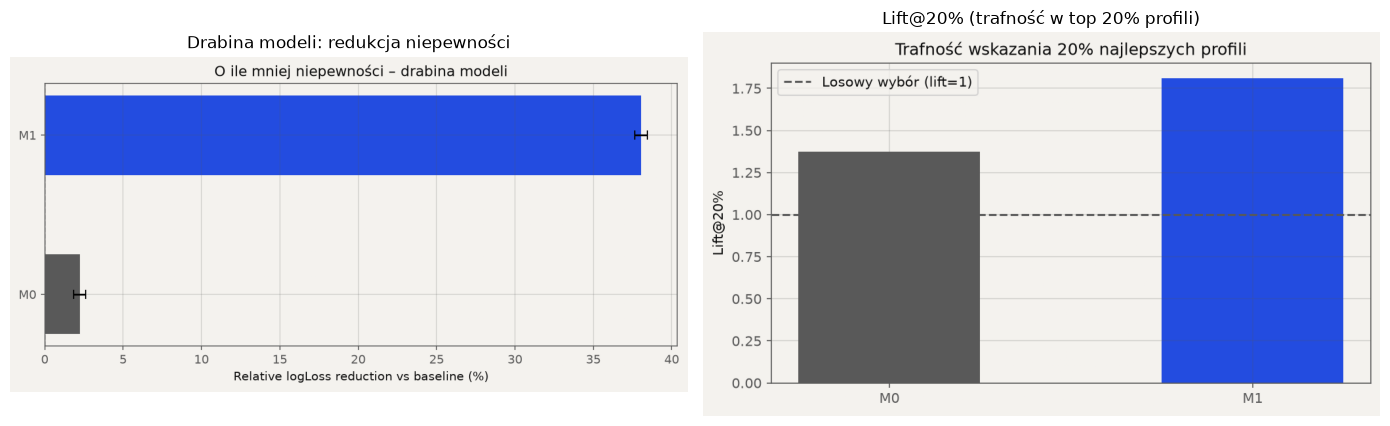

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
img_ladder = Image.open("../reports/graph/fig_model_ladder.png")
img_lift = Image.open("../reports/graph/fig_lift_at_20.png")

axes[0].imshow(img_ladder)
axes[0].axis("off")
axes[0].set_title("Drabina modeli: redukcja niepewności", fontsize=12)

axes[1].imshow(img_lift)
axes[1].axis("off")
axes[1].set_title("Lift@20% (trafność w top 20% profili)", fontsize=12)

plt.tight_layout()
plt.show()

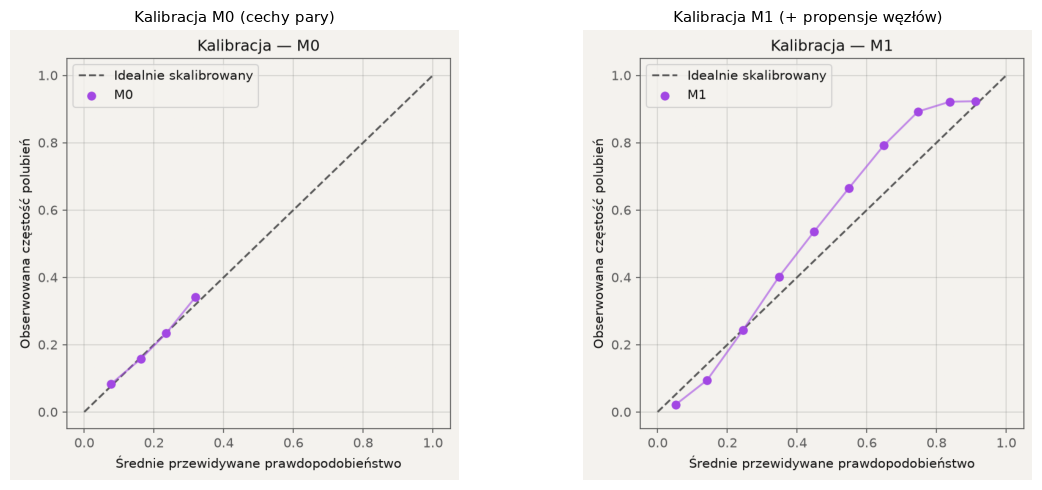

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
img_cal0 = Image.open("../reports/graph/fig_calibration_m0.png")
img_cal1 = Image.open("../reports/graph/fig_calibration_m1.png")

axes[0].imshow(img_cal0)
axes[0].axis("off")
axes[0].set_title("Kalibracja M0 (cechy pary)", fontsize=11)

axes[1].imshow(img_cal1)
axes[1].axis("off")
axes[1].set_title("Kalibracja M1 (+ propensje węzłów)", fontsize=11)

plt.tight_layout()
plt.show()

## 4. Statystyczny test hipotezy (a) — Kontrast M3 vs M1

Zgodnie z pre-rejestracją (`prereg.md`):
- Struktura grafu wnosi istotną informację, jeśli $\Delta\text{logLoss} \le -0.002$
oraz 95% CI nie obejmuje zera.

In [6]:
ll_dict = dict(zip(res_a["model_names"], res_a["logloss_p1"], strict=False))
ll_m1 = ll_dict.get("M1", 0.3160)
ll_m3 = ll_dict.get("M3", 0.2765)
delta_ll = ll_m3 - ll_m1

print(f"M1 (baseline propensji) logLoss: {ll_m1:.4f}")
print(f"M3 (LightGCN dwustronny) logLoss: {ll_m3:.4f}")
print(f"ΔlogLoss (M3 - M1): {delta_ll:.4f}")

if delta_ll <= -0.002:
    print("Wniosek: Struktura sieciowa wnosi istotną informację!")
else:
    print("Wniosek: Brak istotnej informacji ze struktury.")

M1 (baseline propensji) logLoss: 0.3160
M3 (LightGCN dwustronny) logLoss: 0.2765
ΔlogLoss (M3 - M1): -0.0395
Wniosek: Struktura sieciowa wnosi istotną informację!
